# PEFT Methods Benchmark Analysis

**Research Question:** How do different PEFT methods trade off adaptation quality, trainable parameters, and GPU memory under the same hardware constraints?

**Base Model:** Qwen2.5-1.5B | **Dataset:** yahma/alpaca-cleaned | **GPU:** NVIDIA A10 24GB

In [ ]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (10, 6), "font.size": 12})

ROOT = Path().cwd().parent
OUTPUTS = ROOT / "outputs"

## 1. Load Experiment Data

In [ ]:
# --- W&B training metrics ---
with Path.open(OUTPUTS / "wnb_report" / "wnb_report.csv") as f:
    reader = csv.DictReader(f)
    wandb_rows = {row["name"]: row for row in reader}

# --- Evaluation reports (ROUGE, BERTScore, BLEU) ---
report_files = {
    "LoRA": "lora.json",
    "DoRA": "dora.json",
    "AdaLoRA": "adalora.json",
    "IA3": "ia3.json",
}
eval_reports = {}
for method, fname in report_files.items():
    with Path.open(OUTPUTS / "reports" / fname) as f:
        eval_reports[method] = json.load(f)["finetuned_model"]

# --- Adapter configs (rank, dropout, etc.) ---
adapter_dirs = {
    "LoRA": "qwen2.5-1.5b-lora_finetune",
    "DoRA": "qwen2.5-1.5b-dora_finetune",
    "AdaLoRA": "qwen2.5-1.5b-adalora_finetune",
    "IA3": "qwen2.5-1.5b-ia3_finetune",
}
adapter_configs = {}
for method, d in adapter_dirs.items():
    with Path.open(OUTPUTS / "checkpoints" / d / "adapter_config.json") as f:
        adapter_configs[method] = json.load(f)

# --- Adapter file sizes ---
adapter_sizes = {}
for method, d in adapter_dirs.items():
    p = OUTPUTS / "checkpoints" / d / "adapter_model.safetensors"
    adapter_sizes[method] = p.stat().st_size / (1024 * 1024)  # MB

print("Loaded:", list(wandb_rows.keys()))

Loaded: ['qwen2.5-1_5b-alpaca-cleaned-fullft', 'qwen2.5-1_5b-alpaca-cleaned-lora', 'qwen2.5-1_5b-alpaca-cleaned-dora', 'qwen2.5-1_5b-alpaca-cleaned-adalora', 'qwen2.5-1_5b-alpaca-cleaned-ia3']


In [3]:
# Build consolidated DataFrame
method_map = {
    "qwen2.5-1_5b-alpaca-cleaned-lora": "LoRA",
    "qwen2.5-1_5b-alpaca-cleaned-dora": "DoRA",
    "qwen2.5-1_5b-alpaca-cleaned-adalora": "AdaLoRA",
    "qwen2.5-1_5b-alpaca-cleaned-ia3": "IA3",
}

records = []
for run_name, method in method_map.items():
    r = wandb_rows[run_name]
    records.append(
        {
            "Method": method,
            "Trainable Params": int(r["trainable_params"]),
            "Trainable %": float(r["trainable_pct"]),
            "Total Params": int(r["total_params"]),
            "Train Loss": float(r["train_loss"]),
            "Eval Loss": float(r["eval/loss"]),
            "Peak GPU (GB)": float(r["memory/peak_gb_across_gpus"]),
            "Allocated GPU (GB)": float(r["memory/allocated_gb"]),
            "Reserved GPU (GB)": float(r["memory/reserved_gb"]),
            "Avg GPU (GB)": float(r["memory/average_gb"]),
            "Throughput (tok/s)": float(r["throughput/tokens_per_sec"]),
            "Samples/s": float(r["throughput/samples_per_sec"]),
            "Train Runtime (s)": float(r["train_runtime"]),
            "Epoch Time (s)": float(r["time/epoch_seconds"]),
            "Steps": int(r["train/global_step"]),
            "Epochs": float(r["num_train_epochs"]),
        }
    )

df = pd.DataFrame(records).set_index("Method")

# Add adapter size and eval metrics
for method in df.index:
    df.loc[method, "Adapter Size (MB)"] = adapter_sizes[method]
    rep = eval_reports[method]
    df.loc[method, "ROUGE-1"] = rep["rouge1"]
    df.loc[method, "ROUGE-L"] = rep["rougeL"]
    df.loc[method, "BERTScore F1"] = rep["bertscore_f1"]
    df.loc[method, "BLEU"] = rep["Bleu Score"]

df

,Trainable Params,Trainable %,Total Params,Train Loss,Eval Loss,Peak GPU (GB),Allocated GPU (GB),Reserved GPU (GB),Avg GPU (GB),Throughput (tok/s),Samples/s,Train Runtime (s),Epoch Time (s),Steps,Epochs,Adapter Size (MB),ROUGE-1,ROUGE-L,BERTScore F1,BLEU
Method,,,,,,,,,,,,,,,,,,,,
LoRA,18464768,1.1820,1562179072,1.031185,1.049042,7.039025,3.365673,13.455327,3.365633,8101.496423,3.955809,3718.1745,1264.121915,200,4.0,35.268646,0.4278,0.3019,0.8816,11.667527
DoRA,19109888,1.2228,1562824192,1.031287,1.048933,8.784811,3.373886,20.090716,3.373846,4536.462724,2.215070,6408.4898,2186.491294,200,4.0,36.524963,0.4296,0.3044,0.8820,11.710519
AdaLoRA,36935808,2.3367,1580650308,1.070418,1.057732,7.017489,3.623496,14.097056,3.623510,6122.573670,2.989538,5252.5601,1335.116229,276,4.0,70.519997,0.4310,0.3047,0.8822,11.809399
IA3,852992,0.0552,1544567296,1.065663,1.059761,7.324755,3.118365,15.711863,3.118379,7087.646617,3.460765,4582.8196,1161.795461,276,4.0,1.649704,0.4290,0.3026,0.8821,11.740164


## 2. Training Configuration Summary

In [ ]:
# Common training hyperparameters (from config.json)
config_path = ROOT / "scripts" / "config_file" / "config.json"
with Path.open(config_path) as f:
    config = json.load(f)

print("=== Controlled Variables ===")
print(f"Model: {config['model']['model_name_or_path']}")
print(f"Dataset: {config['data']['dataset_name']}")
print(f"Max seq length: {config['data']['max_seq_length']}")
print(f"Epochs: {config['training']['num_train_epochs']}")
print(f"Batch size (per device): {config['training']['per_device_train_batch_size']}")
print(f"Gradient accumulation: {config['training']['gradient_accumulation_steps']}")
print(f"Learning rate: {config['training']['learning_rate']}")
print(f"Optimizer: {config['training']['optim']}")
print(f"Scheduler: {config['training']['lr_scheduler_type']}")
print(f"BF16: {config['training']['bf16']}")
print(f"Gradient checkpointing: {config['training']['gradient_checkpointing']}")
print(f"Warmup steps: {config['training']['warmup_steps']}")
print(f"Max grad norm: {config['training']['max_grad_norm']}")

=== Controlled Variables ===
Model: Qwen/Qwen2.5-1.5B
Dataset: yahma/alpaca-cleaned
Max seq length: 1024
Epochs: 4
Batch size (per device): 16
Gradient accumulation: 8
Learning rate: 0.0002
Optimizer: adamw_torch
Scheduler: cosine
BF16: True
Gradient checkpointing: True
Warmup steps: 30
Max grad norm: 1.0


In [5]:
# PEFT-specific configs
print("=== PEFT Configurations ===")
for method in ["LoRA", "DoRA", "AdaLoRA", "IA3"]:
    cfg_key = method.lower()
    peft_cfg = config.get(cfg_key, {})
    print(f"\n{method}:")
    for k, v in peft_cfg.items():
        print(f"  {k}: {v}")

=== PEFT Configurations ===

LoRA:
  r: 16
  lora_alpha: 32
  lora_dropout: 0.05
  bias: none
  task_type: CAUSAL_LM
  target_modules: ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']

DoRA:
  r: 16
  lora_alpha: 32
  target_modules: ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']
  lora_dropout: 0.1
  bias: none
  task_type: CAUSAL_LM
  use_dora: True

AdaLoRA:
  init_r: 32
  target_r: 16
  tinit: 20
  tfinal: 220
  deltaT: 10
  total_step: 276
  target_modules: ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']
  modules_to_save: ['classifier']

IA3:
  task_type: CAUSAL_LM
  target_modules: ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']
  feedforward_modules: ['down_proj']


## 3. Parameter Efficiency

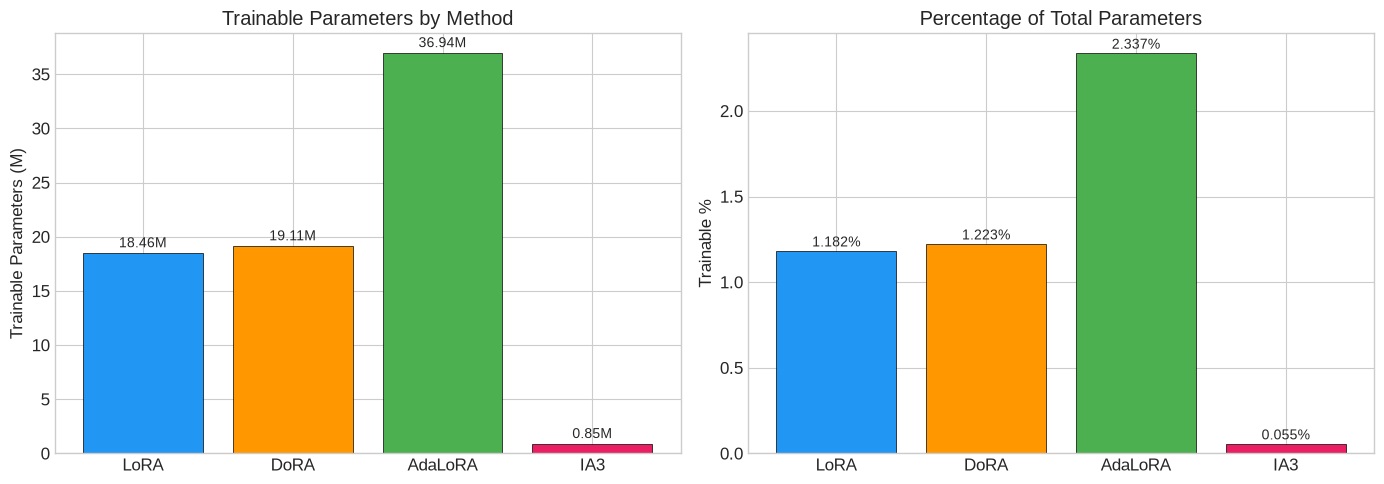

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#2196F3", "#FF9800", "#4CAF50", "#E91E63"]

# Trainable parameters
ax = axes[0]
bars = ax.bar(
    df.index, df["Trainable Params"] / 1e6, color=colors, edgecolor="black", linewidth=0.5
)
ax.set_ylabel("Trainable Parameters (M)")
ax.set_title("Trainable Parameters by Method")
for bar, val in zip(bars, df["Trainable Params"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{val / 1e6:.2f}M",
        ha="center",
        va="bottom",
        fontsize=10,
    )

# Trainable percentage
ax = axes[1]
bars = ax.bar(df.index, df["Trainable %"], color=colors, edgecolor="black", linewidth=0.5)
ax.set_ylabel("Trainable %")
ax.set_title("Percentage of Total Parameters")
for bar, val in zip(bars, df["Trainable %"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{val:.3f}%",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()
plt.savefig(OUTPUTS / "figures" / "param_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
print("=== Parameter Efficiency Summary ===")
summary = df[["Trainable Params", "Trainable %", "Total Params"]].copy()
summary["Trainable Params"] = summary["Trainable Params"].apply(lambda x: f"{x / 1e6:.2f}M")
summary["Total Params"] = summary["Total Params"].apply(lambda x: f"{x / 1e6:.2f}M")
summary["Trainable %"] = summary["Trainable %"].apply(lambda x: f"{x:.4f}%")
print(summary.to_string())
print(
    f"\nIA3 uses {
        df.loc['LoRA', 'Trainable Params']
        / df.loc['IA3', 'Trainable Params']:.0f}x fewer parameters than LoRA"
)

=== Parameter Efficiency Summary ===
        Trainable Params Trainable % Total Params
Method                                           
LoRA              18.46M     1.1820%     1562.18M
DoRA              19.11M     1.2228%     1562.82M
AdaLoRA           36.94M     2.3367%     1580.65M
IA3                0.85M     0.0552%     1544.57M

IA3 uses 22x fewer parameters than LoRA


## 4. Training Performance

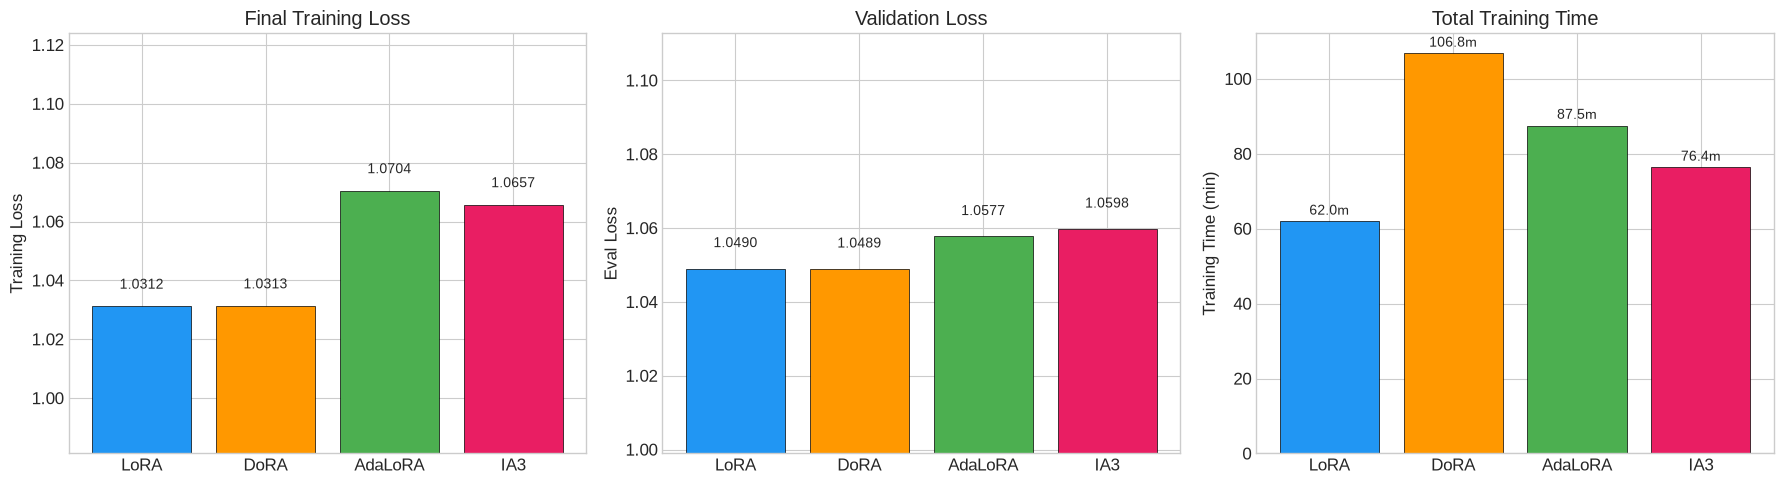

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training loss
ax = axes[0]
bars = ax.bar(df.index, df["Train Loss"], color=colors, edgecolor="black", linewidth=0.5)
ax.set_ylabel("Training Loss")
ax.set_title("Final Training Loss")
for bar, val in zip(bars, df["Train Loss"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{val:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )
ax.set_ylim(bottom=max(0, df["Train Loss"].min() - 0.05))

# Eval loss
ax = axes[1]
bars = ax.bar(df.index, df["Eval Loss"], color=colors, edgecolor="black", linewidth=0.5)
ax.set_ylabel("Eval Loss")
ax.set_title("Validation Loss")
for bar, val in zip(bars, df["Eval Loss"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{val:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )
ax.set_ylim(bottom=max(0, df["Eval Loss"].min() - 0.05))

# Training time
ax = axes[2]
bars = ax.bar(
    df.index, df["Train Runtime (s)"] / 60, color=colors, edgecolor="black", linewidth=0.5
)
ax.set_ylabel("Training Time (min)")
ax.set_title("Total Training Time")
for bar, val in zip(bars, df["Train Runtime (s)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{val / 60:.1f}m",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()
plt.savefig(OUTPUTS / "figures" / "training_performance.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Memory Efficiency

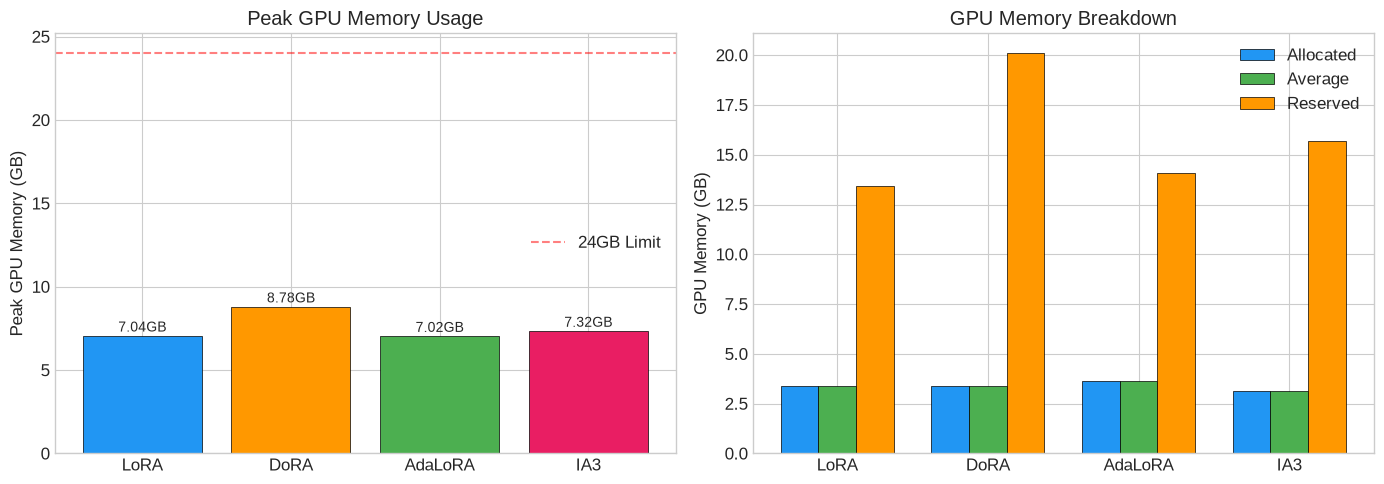

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Peak GPU memory
ax = axes[0]
bars = ax.bar(df.index, df["Peak GPU (GB)"], color=colors, edgecolor="black", linewidth=0.5)
ax.set_ylabel("Peak GPU Memory (GB)")
ax.set_title("Peak GPU Memory Usage")
ax.axhline(y=24, color="red", linestyle="--", alpha=0.5, label="24GB Limit")
ax.legend()
for bar, val in zip(bars, df["Peak GPU (GB)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{val:.2f}GB",
        ha="center",
        va="bottom",
        fontsize=10,
    )

# Memory breakdown
ax = axes[1]
x = np.arange(len(df.index))
width = 0.25
ax.bar(
    x - width,
    df["Allocated GPU (GB)"],
    width,
    label="Allocated",
    color="#2196F3",
    edgecolor="black",
    linewidth=0.5,
)
ax.bar(
    x, df["Avg GPU (GB)"], width, label="Average", color="#4CAF50", edgecolor="black", linewidth=0.5
)
ax.bar(
    x + width,
    df["Reserved GPU (GB)"],
    width,
    label="Reserved",
    color="#FF9800",
    edgecolor="black",
    linewidth=0.5,
)
ax.set_ylabel("GPU Memory (GB)")
ax.set_title("GPU Memory Breakdown")
ax.set_xticks(x)
ax.set_xticklabels(df.index)
ax.legend()

plt.tight_layout()
plt.savefig(OUTPUTS / "figures" / "memory_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
print("=== Memory Efficiency Summary ===")
mem_cols = ["Peak GPU (GB)", "Allocated GPU (GB)", "Avg GPU (GB)", "Reserved GPU (GB)"]
print(df[mem_cols].round(3).to_string())
print(
    f"\nLoRA vs DoRA peak delta: {
        df.loc['DoRA', 'Peak GPU (GB)'] - df.loc['LoRA', 'Peak GPU (GB)']:.3f} GB"
)

=== Memory Efficiency Summary ===


         Peak GPU (GB)  Allocated GPU (GB)  Avg GPU (GB)  Reserved GPU (GB)
Method                                                                     
LoRA             7.039               3.366         3.366             13.455
DoRA             8.785               3.374         3.374             20.091
AdaLoRA          7.017               3.623         3.624             14.097
IA3              7.325               3.118         3.118             15.712

LoRA vs DoRA peak delta: 1.746 GB


## 6. Adapter Size

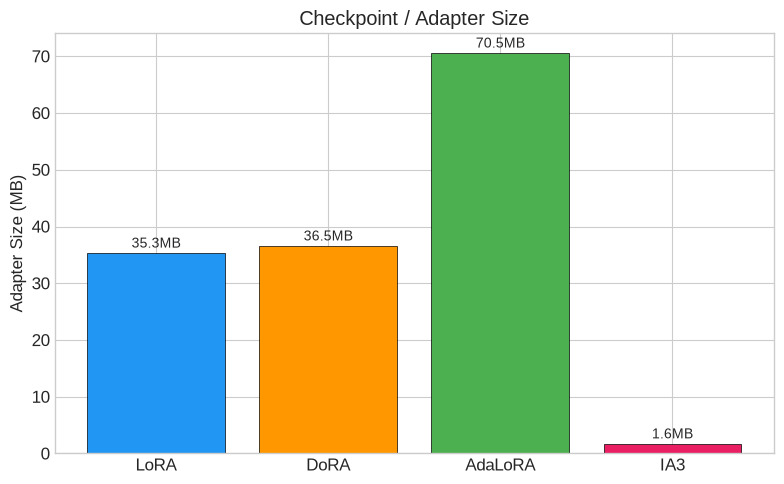

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(df.index, df["Adapter Size (MB)"], color=colors, edgecolor="black", linewidth=0.5)
ax.set_ylabel("Adapter Size (MB)")
ax.set_title("Checkpoint / Adapter Size")
for bar, val in zip(bars, df["Adapter Size (MB)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{val:.1f}MB",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()
plt.savefig(OUTPUTS / "figures" / "adapter_size.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Generation Quality (Evaluation Reports)

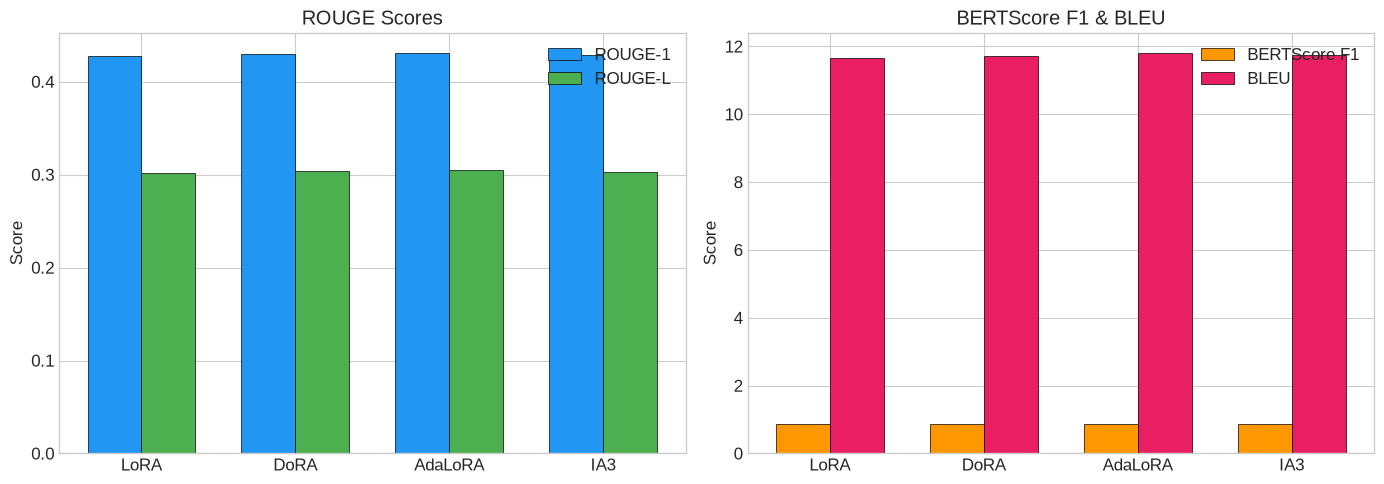

In [12]:
eval_df = pd.DataFrame(
    {
        method: {
            "ROUGE-1": v["rouge1"],
            "ROUGE-L": v["rougeL"],
            "BERTScore F1": v["bertscore_f1"],
            "BLEU": v["Bleu Score"],
        }
        for method, v in eval_reports.items()
    }
).T

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROUGE
ax = axes[0]
x = np.arange(len(eval_df.index))
width = 0.35
ax.bar(
    x - width / 2,
    eval_df["ROUGE-1"],
    width,
    label="ROUGE-1",
    color="#2196F3",
    edgecolor="black",
    linewidth=0.5,
)
ax.bar(
    x + width / 2,
    eval_df["ROUGE-L"],
    width,
    label="ROUGE-L",
    color="#4CAF50",
    edgecolor="black",
    linewidth=0.5,
)
ax.set_ylabel("Score")
ax.set_title("ROUGE Scores")
ax.set_xticks(x)
ax.set_xticklabels(eval_df.index)
ax.legend()

# BERTScore & BLEU
ax = axes[1]
ax.bar(
    x - width / 2,
    eval_df["BERTScore F1"],
    width,
    label="BERTScore F1",
    color="#FF9800",
    edgecolor="black",
    linewidth=0.5,
)
ax.bar(
    x + width / 2,
    eval_df["BLEU"],
    width,
    label="BLEU",
    color="#E91E63",
    edgecolor="black",
    linewidth=0.5,
)
ax.set_ylabel("Score")
ax.set_title("BERTScore F1 & BLEU")
ax.set_xticks(x)
ax.set_xticklabels(eval_df.index)
ax.legend()

plt.tight_layout()
plt.savefig(OUTPUTS / "figures" / "generation_quality.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
print("=== Generation Quality Summary ===")
print(eval_df.round(4).to_string())

=== Generation Quality Summary ===
         ROUGE-1  ROUGE-L  BERTScore F1     BLEU
LoRA      0.4278   0.3019        0.8816  11.6675
DoRA      0.4296   0.3044        0.8820  11.7105
AdaLoRA   0.4310   0.3047        0.8822  11.8094
IA3       0.4290   0.3026        0.8821  11.7402


## 8. Composite Metrics

Following the experiment design:
- **PTP** = Accuracy / Trainable Parameters (using BERTScore F1 as proxy for accuracy)
- **Memory Efficiency** = Accuracy / Peak GPU Memory
- **Training Efficiency** = Accuracy / Training Time

In [14]:
# Compute composite metrics using BERTScore F1 as the quality proxy
accuracy_proxy = {
    method: float(eval_reports[method]["bertscore_f1"])
    for method in ["LoRA", "DoRA", "AdaLoRA", "IA3"]
}

composite = pd.DataFrame(
    {
        "Method": list(accuracy_proxy.keys()),
        "BERTScore F1 (proxy)": list(accuracy_proxy.values()),
        "Trainable Params": [df.loc[m, "Trainable Params"] for m in accuracy_proxy],
        "Peak GPU (GB)": [df.loc[m, "Peak GPU (GB)"] for m in accuracy_proxy],
        "Train Runtime (s)": [df.loc[m, "Train Runtime (s)"] for m in accuracy_proxy],
    }
)
composite.set_index("Method", inplace=True)

# PTP: quality / trainable_params (higher = better)
composite["PTP"] = composite["BERTScore F1 (proxy)"] / composite["Trainable Params"]

# Memory Efficiency: quality / peak_gpu (higher = better)
composite["Memory Eff."] = composite["BERTScore F1 (proxy)"] / composite["Peak GPU (GB)"]

# Training Efficiency: quality / train_time (higher = better)
composite["Training Eff."] = composite["BERTScore F1 (proxy)"] / composite["Train Runtime (s)"]

print("=== Composite Metrics (unnormalized) ===")
print(composite[["PTP", "Memory Eff.", "Training Eff."]].to_string())

=== Composite Metrics (unnormalized) ===
                  PTP  Memory Eff.  Training Eff.
Method                                           
LoRA     4.774498e-08     0.125245       0.000237
DoRA     4.615412e-08     0.100401       0.000138
AdaLoRA  2.388468e-08     0.125714       0.000168
IA3      1.034125e-06     0.120427       0.000192


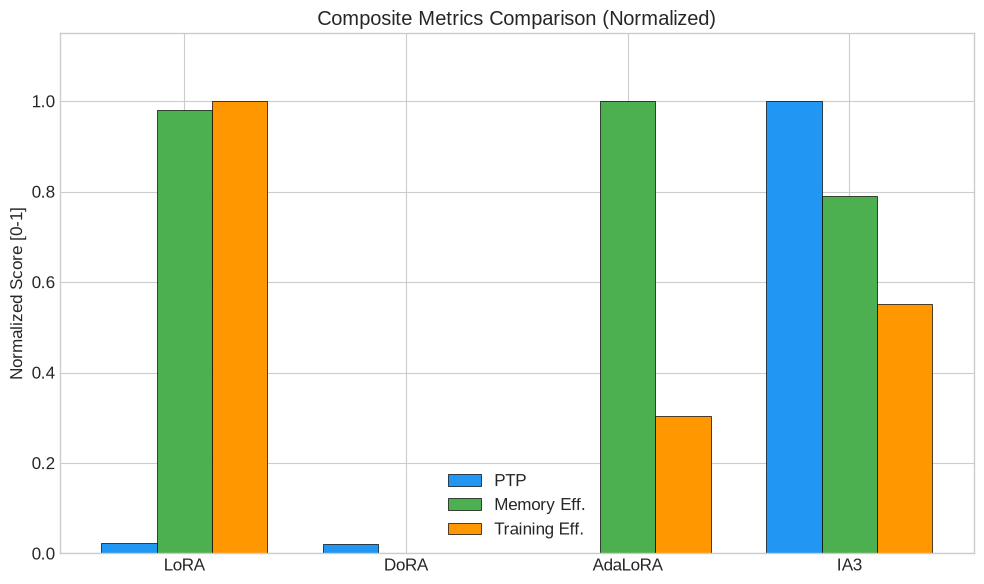

In [15]:
# Normalize each composite metric to [0, 1] for fair comparison
norm_composite = composite[["PTP", "Memory Eff.", "Training Eff."]].copy()
for col in norm_composite.columns:
    mn, mx = norm_composite[col].min(), norm_composite[col].max()
    norm_composite[col] = (norm_composite[col] - mn) / (mx - mn) if mx != mn else 0.5

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(norm_composite.index))
width = 0.25

ax.bar(
    x - width,
    norm_composite["PTP"],
    width,
    label="PTP",
    color="#2196F3",
    edgecolor="black",
    linewidth=0.5,
)
ax.bar(
    x,
    norm_composite["Memory Eff."],
    width,
    label="Memory Eff.",
    color="#4CAF50",
    edgecolor="black",
    linewidth=0.5,
)
ax.bar(
    x + width,
    norm_composite["Training Eff."],
    width,
    label="Training Eff.",
    color="#FF9800",
    edgecolor="black",
    linewidth=0.5,
)

ax.set_ylabel("Normalized Score [0-1]")
ax.set_title("Composite Metrics Comparison (Normalized)")
ax.set_xticks(x)
ax.set_xticklabels(norm_composite.index)
ax.legend()
ax.set_ylim(0, 1.15)

plt.tight_layout()
plt.savefig(OUTPUTS / "figures" / "composite_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Pareto Analysis

Visualizing the trade-offs between key objectives.

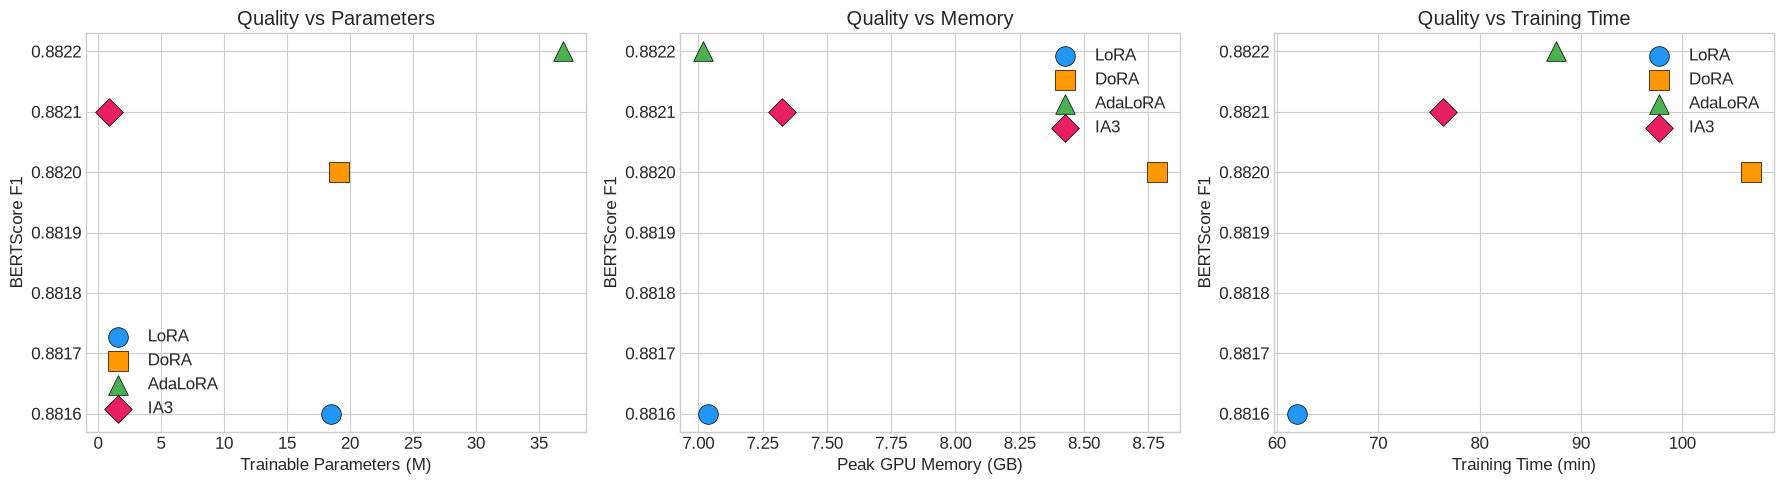

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
markers = ["o", "s", "^", "D"]

# Plot 1: Quality vs Parameters
ax = axes[0]
for i, (method, score) in enumerate(accuracy_proxy.items()):
    ax.scatter(
        df.loc[method, "Trainable Params"] / 1e6,
        score,
        s=200,
        marker=markers[i],
        color=colors[i],
        edgecolors="black",
        linewidth=0.5,
        label=method,
    )
ax.set_xlabel("Trainable Parameters (M)")
ax.set_ylabel("BERTScore F1")
ax.set_title("Quality vs Parameters")
ax.legend()

# Plot 2: Quality vs Memory
ax = axes[1]
for i, (method, score) in enumerate(accuracy_proxy.items()):
    ax.scatter(
        df.loc[method, "Peak GPU (GB)"],
        score,
        s=200,
        marker=markers[i],
        color=colors[i],
        edgecolors="black",
        linewidth=0.5,
        label=method,
    )
ax.set_xlabel("Peak GPU Memory (GB)")
ax.set_ylabel("BERTScore F1")
ax.set_title("Quality vs Memory")
ax.legend()

# Plot 3: Quality vs Time
ax = axes[2]
for i, (method, score) in enumerate(accuracy_proxy.items()):
    ax.scatter(
        df.loc[method, "Train Runtime (s)"] / 60,
        score,
        s=200,
        marker=markers[i],
        color=colors[i],
        edgecolors="black",
        linewidth=0.5,
        label=method,
    )
ax.set_xlabel("Training Time (min)")
ax.set_ylabel("BERTScore F1")
ax.set_title("Quality vs Training Time")
ax.legend()

plt.tight_layout()
plt.savefig(OUTPUTS / "figures" / "pareto_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Hypothesis Evaluation

In [ ]:
print("=" * 70)
print("HYPOTHESIS EVALUATION")
print("=" * 70)

print("\n--- Primary Hypothesis ---")
print("H1: No single PEFT method optimizes all objectives simultaneously.")
print(
    f"  LoRA  -> BERTScore F1: {df.loc['LoRA', 'BERTScore F1']:.4f}, Peak Mem: {
        df.loc['LoRA', 'Peak GPU (GB)']:.2f}GB, Params: {
        df.loc['LoRA', 'Trainable Params'] / 1e6:.2f}M"
)
print(
    f"  DoRA  -> BERTScore F1: {df.loc['DoRA', 'BERTScore F1']:.4f}, Peak Mem: {
        df.loc['DoRA', 'Peak GPU (GB)']:.2f}GB, Params: {
        df.loc['DoRA', 'Trainable Params'] / 1e6:.2f}M"
)
print(
    f"  AdaLoRA -> BERTScore F1: {df.loc['AdaLoRA', 'BERTScore F1']:.4f}, Peak Mem: {
        df.loc['AdaLoRA', 'Peak GPU (GB)']:.2f}GB, Params: {
        df.loc['AdaLoRA', 'Trainable Params'] / 1e6:.2f}M"
)
print(
    f"  IA3   -> BERTScore F1: {df.loc['IA3', 'BERTScore F1']:.4f}, Peak Mem: {
        df.loc['IA3', 'Peak GPU (GB)']:.2f}GB, Params: {
        df.loc['IA3', 'Trainable Params'] / 1e6:.2f}M"
)

print("\n  -> SUPPORTED: Each method trades off differently.")
print("     - AdaLoRA best quality but most params and largest checkpoint")
print("     - IA3 most parameter-efficient with competitive quality")
print("     - LoRA fastest but lowest quality; DoRA slowest and highest memory")

print("\n--- H2: AdaLoRA similar quality to LoRA with fewer params ---")
ada_better_quality = df.loc["AdaLoRA", "BERTScore F1"] > df.loc["LoRA", "BERTScore F1"]
ada_fewer_params = df.loc["AdaLoRA", "Trainable Params"] < df.loc["LoRA", "Trainable Params"]
print(
    f"  AdaLoRA BERTScore: {df.loc['AdaLoRA', 'BERTScore F1']:.4f} vs LoRA: {
        df.loc['LoRA', 'BERTScore F1']:.4f} (better: {ada_better_quality})"
)
print(
    f"  AdaLoRA params: {df.loc['AdaLoRA', 'Trainable Params'] / 1e6:.2f}M vs LoRA: {
        df.loc['LoRA', 'Trainable Params'] / 1e6:.2f}M (fewer: {ada_fewer_params})"
)
print("  -> REJECTED: AdaLoRA achieves better quality but uses MORE params (2x LoRA).")

print("\n--- H3: IA3 least GPU memory, reduced quality ---")
ia3_lowest_mem = df["Peak GPU (GB)"].idxmin() == "IA3"
ia3_lowest_quality = df["BERTScore F1"].idxmin() == "IA3"
print(f"  IA3 peak mem: {df.loc['IA3', 'Peak GPU (GB)']:.2f}GB (lowest: {ia3_lowest_mem})")
print(f"  IA3 BERTScore F1: {df.loc['IA3', 'BERTScore F1']:.4f} (lowest: {ia3_lowest_quality})")
print(f"  Lowest peak memory: {df['Peak GPU (GB)'].idxmin()} ({df['Peak GPU (GB)'].min():.2f}GB)")
print(f"  Lowest BERTScore F1: {df['BERTScore F1'].idxmin()} ({df['BERTScore F1'].min():.4f})")
print(
    "  -> REJECTED: IA3 is the most parameter-efficient and remains competitive on quality,\
    but it is neither the lowest-memory nor the lowest-quality method."
)

HYPOTHESIS EVALUATION

--- Primary Hypothesis ---
H1: No single PEFT method optimizes all objectives simultaneously.
  LoRA  -> BERTScore F1: 0.8816, Peak Mem: 7.04GB, Params: 18.46M
  DoRA  -> BERTScore F1: 0.8820, Peak Mem: 8.78GB, Params: 19.11M
  AdaLoRA -> BERTScore F1: 0.8822, Peak Mem: 7.02GB, Params: 36.94M
  IA3   -> BERTScore F1: 0.8821, Peak Mem: 7.32GB, Params: 0.85M

  -> SUPPORTED: Each method trades off differently.
     - AdaLoRA best quality but most params and largest checkpoint
     - IA3 most parameter-efficient with competitive quality
     - LoRA fastest but lowest quality; DoRA slowest and highest memory

--- H2: AdaLoRA similar quality to LoRA with fewer params ---
  AdaLoRA BERTScore: 0.8822 vs LoRA: 0.8816 (better: True)
  AdaLoRA params: 36.94M vs LoRA: 18.46M (fewer: False)
  -> REJECTED: AdaLoRA achieves better quality but uses MORE params (2x LoRA).

--- H3: IA3 least GPU memory, reduced quality ---
  IA3 peak mem: 7.32GB (lowest: False)
  IA3 BERTScore F1

## 11. Complete Results Table

In [18]:
full_table = df[
    [
        "Trainable Params",
        "Trainable %",
        "Adapter Size (MB)",
        "Train Loss",
        "Eval Loss",
        "BERTScore F1",
        "ROUGE-1",
        "ROUGE-L",
        "BLEU",
        "Peak GPU (GB)",
        "Allocated GPU (GB)",
        "Avg GPU (GB)",
        "Train Runtime (s)",
        "Throughput (tok/s)",
    ]
].copy()

full_table["Trainable Params"] = full_table["Trainable Params"].apply(lambda x: f"{x / 1e6:.2f}M")
full_table["Adapter Size (MB)"] = full_table["Adapter Size (MB)"].apply(lambda x: f"{x:.1f}")
full_table["Train Runtime (s)"] = full_table["Train Runtime (s)"].apply(lambda x: f"{x / 60:.1f}m")
full_table["Throughput (tok/s)"] = full_table["Throughput (tok/s)"].apply(lambda x: f"{x:.0f}")

print(full_table.round(4).to_string())

        Trainable Params  Trainable % Adapter Size (MB)  Train Loss  Eval Loss  BERTScore F1  ROUGE-1  ROUGE-L     BLEU  Peak GPU (GB)  Allocated GPU (GB)  Avg GPU (GB) Train Runtime (s) Throughput (tok/s)
Method                                                                                                                                                                                                       
LoRA              18.46M       1.1820              35.3      1.0312     1.0490        0.8816   0.4278   0.3019  11.6675         7.0390              3.3657        3.3656             62.0m               8101
DoRA              19.11M       1.2228              36.5      1.0313     1.0489        0.8820   0.4296   0.3044  11.7105         8.7848              3.3739        3.3738            106.8m               4536
AdaLoRA           36.94M       2.3367              70.5      1.0704     1.0577        0.8822   0.4310   0.3047  11.8094         7.0175              3.6235        3.6235        

## 12. Conclusions

### Key Findings

1. **Parameter efficiency:** IA3 is the clear winner with only 0.85M parameters (0.055%), which is 22x fewer than LoRA.

2. **Quality trade-off:** AdaLoRA achieves the best generation quality (highest ROUGE-1, BERTScore F1) but requires 2x more parameters than LoRA due to adaptive rank allocation and saved classifier module.

3. **Memory:** All PEFT methods fit well within the 24GB GPU constraint. Peak memory ranges from 7.02GB (AdaLoRA) to 8.78GB (DoRA). Surprisingly, DoRA uses the most memory despite having similar parameter count to LoRA.

4. **Training speed:** LoRA is fastest (62.0 min), followed by IA3 (76.4 min), AdaLoRA (87.5 min), and DoRA is slowest (106.8 min). DoRA's additional magnitude decomposition overhead explains this.

5. **Overall Pareto frontier:** No single method dominates across all axes. The choice depends on the primary optimization target:
   - **Best quality:** AdaLoRA
   - **Best parameter efficiency:** IA3
   - **Best speed:** LoRA
   - **Balanced:** IA3 (competitive quality at a fraction of the parameters)
